# Diagnóstico de cancro da mama — Passive Learning (baseline)

**Inteligência Artificial Centrada no Humano** · Mestrado em Inteligência Artificial e Engenharia de Dados · FCTUC

Treina dois modelos com **todo** o conjunto de treino anotado: uma CNN treinada de raiz e uma MobileNetV2 pré-treinada (*transfer learning*). Os resultados servem de referência para o Active Learning (`02_active_learning.ipynb`), que usa muito menos imagens anotadas.

## 1. Configuração

Importa o código partilhado de `src/` (abrir o notebook a partir da pasta `notebooks/`, com o kernel do `.venv`), lê os caminhos de `src/config.py` e prepara a **GPU** com `setup_gpu()` (`src/gpu.py`), que diz se o treino vai correr na GPU ou no CPU.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent   # raiz do repositório (o notebook está em notebooks/)
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, MODELS_PATH, RESULTS_PATH
from src.gpu import setup_gpu

setup_gpu()

A treinar na GPU: NVIDIA GeForce RTX 3050 Laptop GPU


True

### Parâmetros
- **`IMG_SIZE`**: as imagens são redimensionadas para 128×128 (escolha explicada no notebook 00).
- **`LEARNING_RATE`**: tamanho dos passos que o otimizador dá ao ajustar os pesos.
- **`MAX_EPOCHS`** e **`PATIENCE`**: o treino pára sozinho (*early stopping*) quando a loss de validação não melhora durante `PATIENCE` épocas seguidas, até um máximo de `MAX_EPOCHS`.
- **`SEEDS`**: cada modelo é treinado 5 vezes, com inicializações aleatórias diferentes. Com um teste de 149 imagens e uma validação de 127, uma única corrida pode ter sorte ou azar; a média e o desvio padrão são mais fiáveis. O treino é determinístico (`setup_gpu`): a mesma seed dá sempre o mesmo resultado.

In [2]:
# Parâmetros
IMG_SIZE = 128
LEARNING_RATE = 0.001
MAX_EPOCHS = 60
PATIENCE = 10
SEEDS = [1, 2, 3, 4, 5]

## 2. Dados

`load_dataset` (em `src/data.py`) faz cinco passos:

1. **Ler** as imagens em escala de cinzento e redimensionar para `IMG_SIZE × IMG_SIZE`. Os valores dos píxeis passam de 0–255 para 0–1 (normalização), o que ajuda o treino a convergir.
2. **Tirar a classe do nome do ficheiro**: `0 = normal`, `1 = benign`, `2 = malignant`. Excluem-se as imagens repetidas com labels contraditórias (notebook 00).
3. **Dividir em três conjuntos**, de forma estratificada (cada um fica com as mesmas proporções de classes) e **por grupos**: as cópias da mesma ecografia ficam sempre no mesmo conjunto.
   - **treino (~64%)**: as imagens com que o modelo aprende;
   - **validação (~17%)**: para acompanhar o treino e escolher parâmetros (quando parar o treino, regularização…);
   - **teste (~20%)**: só para a avaliação final.
4. **Balancear só o treino** com rotações de 90º e reflexões. A validação e o teste ficam com as imagens originais, para medir o desempenho em condições reais.
5. **Baralhar o treino**, para as classes ficarem misturadas.

> **Porquê dividir por grupos e antes de balancear?** Se uma cópia de uma ecografia (repetida noutro ficheiro, ou rodada no balanceamento) ficasse no treino e outra na validação ou no teste, o modelo seria avaliado com imagens que já viu (*data leakage*), e os resultados seriam otimistas e falsos. Assim, **nenhuma imagem de validação ou de teste, nem uma cópia dela, é usada no treino.**

In [3]:
# Carregar, dividir em treino/validação/teste e balancear só o treino
import numpy as np
from src.data import CLASSES, load_dataset, summarize

x_train, x_val, x_test, y_train, y_val, y_test = load_dataset(DATA_PATH, size=IMG_SIZE)
summarize(x_train, x_val, x_test, y_train, y_val, y_test)

Treino: (1554, 128, 128), validação: (127, 128, 128), teste: (149, 128, 128)
Memória das imagens: 120 MB
Treino: {'normal': 492, 'benign': 550, 'malignant': 512}
Validação: {'normal': 21, 'benign': 69, 'malignant': 37}
Teste: {'normal': 28, 'benign': 82, 'malignant': 39}


## 3. Modelos

### O que é uma CNN?
Uma **Rede Neuronal Convolucional** aprende sozinha que padrões da imagem (contornos, texturas, formas) ajudam a distinguir as classes. As primeiras camadas detetam padrões simples, como arestas; as seguintes combinam-nos em padrões mais complexos, como a forma de uma lesão.

### Modelo 1 — CNN treinada de raiz (`build_cnn` em `src/model.py`)
- **4 blocos convolucionais** com 32 → 64 → 128 → 32 filtros de 4×4. Cada bloco tem:
  - `Conv2D` + ReLU: aplica os filtros e deteta padrões;
  - `BatchNormalization`: normaliza as ativações, o que estabiliza o treino;
  - `MaxPooling2D`: reduz a imagem para metade, guardando só os valores mais fortes;
  - `Dropout(0.3)` nos blocos 2 e 3: desliga 30% dos neurónios ao acaso em cada passo, para o modelo não decorar o treino (*overfitting*).
- **`Flatten` + `Dense(32)`**: junta tudo num vetor e combina os padrões encontrados.
- **`Dense(3, softmax)`**: devolve 3 probabilidades que somam 1, uma por classe. A classe prevista é a de maior probabilidade.

**Como chegámos às definições.** Na primeira configuração que testámos (learning rate 0.00001, 15 épocas, sigmoid na camada `Dense(32)`), o modelo quase não aprendia: a accuracy de validação ficou em 17% (dizia "normal" a tudo) durante 8 épocas e o teste acabou em 36%, pior do que dizer sempre "benigno" (56%). Isto é *underfitting*. Mudámos:
1. **learning rate 0.00001 → 0.001**: passos 100× maiores, o modelo aprende em poucas épocas;
2. **early stopping** em vez de um nº fixo de épocas: treina enquanto a validação melhorar e guarda a melhor época;
3. **ReLU em vez de sigmoid** na camada `Dense(32)` (a sigmoid satura e atrasa a aprendizagem) e mais um `Dropout` antes da saída.

### Modelo 2 — MobileNetV2 pré-treinada (*transfer learning*, `build_mobilenet`)
O treino tem só 485 imagens originais (~380 ecografias diferentes): é pouco para uma CNN aprender de raiz o que é um contorno ou uma textura. A **MobileNetV2** já foi treinada com 1,4 milhões de imagens do ImageNet e já sabe detetar esses padrões genéricos. Reaproveitamo-la em duas fases:
1. **Rede congelada**: os pesos da MobileNetV2 não mudam; só se treina uma nova camada de saída com as nossas 3 classes.
2. ***Fine-tuning***: descongelam-se as últimas 30 camadas e continua-se a treinar com um learning rate 10× menor, para as adaptar às ecografias sem estragar o que já sabiam.

A MobileNetV2 espera imagens a cores (3 canais) com valores entre −1 e 1: a imagem em escala de cinzento é repetida 3 vezes e reescalada. Escolhemo-la porque é pequena (3,5 M parâmetros) e cabe na GPU de 4 GB.

**Outras alternativas testadas.** Antes de fixar estas escolhas testámos variantes: learning rates diferentes, só a MobileNetV2 congelada (sem fine-tuning), fine-tuning com learning rate menor, imagens 224×224 e pesos por classe (um erro num maligno a contar 1.5× mais na loss). Nenhuma foi melhor do que as configurações acima; os números estão no relatório (experiências preliminares).

## 4. Treino

`fit` (em `src/model.py`) treina com early stopping, usando **só** o conjunto de validação para decidir quando parar. Depois de cada treino guardam-se as previsões no teste e a memória da GPU é libertada. A MobileNetV2 da primeira seed fica guardada em `models/mobilenet.keras`, para o Grad-CAM (notebook 03) e o agente a usarem sem treinar outra vez.

São 2 modelos × 5 seeds = 10 treinos de ~2 minutos cada na GPU.

In [4]:
import gc
import time

from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from src.evaluation import compute_metrics
from src.model import build_cnn, build_mobilenet, fit, unfreeze_top

y_train_one_hot = to_categorical(y_train, num_classes=len(CLASSES))
y_val_one_hot = to_categorical(y_val, num_classes=len(CLASSES))
data = (x_train, y_train_one_hot, x_val, y_val_one_hot)

runs = {"cnn": [], "mobilenet": []}   # runs[modelo] = lista com o resultado de cada seed
for seed in SEEDS:
    for name in runs:
        keras.utils.set_random_seed(seed)   # mesma seed = mesma inicialização e mesma ordem dos batches
        start = time.time()
        if name == "cnn":
            model = build_cnn(size=IMG_SIZE, learning_rate=LEARNING_RATE)
            histories = [fit(model, *data, max_epochs=MAX_EPOCHS, patience=PATIENCE)]
        else:
            model = build_mobilenet(size=IMG_SIZE, learning_rate=LEARNING_RATE)
            histories = [fit(model, *data, max_epochs=MAX_EPOCHS, patience=PATIENCE)]             # fase 1: congelada
            unfreeze_top(model, n_layers=30, learning_rate=LEARNING_RATE / 10)
            histories.append(fit(model, *data, max_epochs=MAX_EPOCHS, patience=PATIENCE))       # fase 2: fine-tuning

        y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
        if name == "mobilenet" and seed == SEEDS[0]:
            model.save(MODELS_PATH / "mobilenet.keras")   # usado no Grad-CAM (notebook 03) e no agente
        runs[name].append({
            "seed": seed,
            "epochs": [len(h.history["loss"]) for h in histories],
            "seconds": round(time.time() - start),
            "history": {k: [float(v) for h in histories for v in h.history[k]] for k in histories[0].history},
            "y_pred": y_pred.tolist(),
            "metrics": compute_metrics(y_test, y_pred),
        })
        r = runs[name][-1]
        print(f"{name:10s} seed {seed}: {r['seconds']:4d} s, épocas {r['epochs']}, accuracy {r['metrics']['accuracy']:.3f}, "
              f"recall maligno {r['metrics']['recall_malignant']:.3f}")
        del model
        keras.backend.clear_session()
        gc.collect()

cnn        seed 1:   90 s, épocas [25], accuracy 0.591, recall maligno 0.718


mobilenet  seed 1:   91 s, épocas [34, 17], accuracy 0.799, recall maligno 0.744


cnn        seed 2:   81 s, épocas [23], accuracy 0.638, recall maligno 0.769


mobilenet  seed 2:   72 s, épocas [21, 17], accuracy 0.779, recall maligno 0.615


cnn        seed 3:   95 s, épocas [27], accuracy 0.711, recall maligno 0.795


mobilenet  seed 3:   75 s, épocas [21, 19], accuracy 0.839, recall maligno 0.718


cnn        seed 4:   91 s, épocas [26], accuracy 0.550, recall maligno 0.769


mobilenet  seed 4:   77 s, épocas [24, 18], accuracy 0.819, recall maligno 0.667


cnn        seed 5:  112 s, épocas [32], accuracy 0.557, recall maligno 0.538


mobilenet  seed 5:   78 s, épocas [27, 16], accuracy 0.785, recall maligno 0.744


### Curvas de treino (seed 1)
Accuracy e loss em cada época, no treino e na validação. O que procurar:
- as duas curvas a melhorar juntas: o modelo está a aprender padrões que generalizam;
- o treino a melhorar e a validação parada ou a piorar: *overfitting* (o modelo está a decorar o treino). O early stopping pára o treino pouco depois disto começar;
- as duas curvas quase paradas: *underfitting*.

Na MobileNetV2, a linha vertical marca o início do fine-tuning. Nesse momento há um salto: ao descongelar camadas, os pesos começam a mudar e o modelo piora por umas épocas antes de recuperar no treino. A loss de validação sobe durante o fine-tuning, mas a accuracy no teste foi melhor com fine-tuning do que sem ele (experiências preliminares, no relatório). Com só 127 imagens de validação, estas curvas são ruidosas e não contam a história toda.

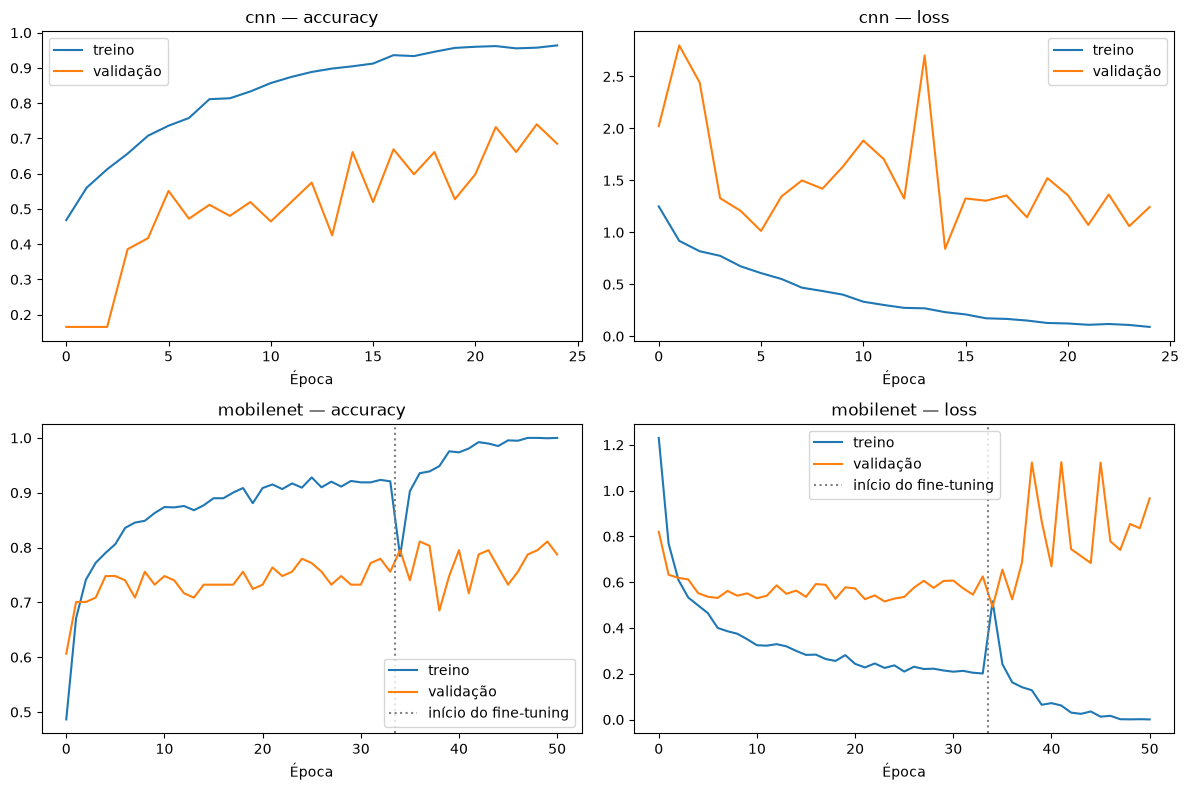

In [5]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
for row, name in zip(axs, runs):
    run = runs[name][0]
    for ax, metric in zip(row, ["accuracy", "loss"]):
        ax.plot(run["history"][metric], label="treino")
        ax.plot(run["history"][f"val_{metric}"], label="validação")
        if len(run["epochs"]) > 1:
            ax.axvline(run["epochs"][0] - 0.5, color="gray", linestyle="dotted", label="início do fine-tuning")
        ax.set_xlabel("Época")
        ax.set_title(f"{name} — {metric}")
        ax.legend()
plt.tight_layout()
plt.show()

## 5. Avaliação

Os modelos são avaliados no **conjunto de teste**, que nunca viram durante o treino.

| Métrica | O que mede |
|---|---|
| **Accuracy** | % de imagens bem classificadas. Pode enganar quando as classes não estão equilibradas. |
| **Recall de maligno** | Dos cancros reais, quantos foram detetados. **É a métrica mais importante do projeto.** |
| **Falsos negativos (FN)** | Nº de cancros classificados como benignos ou normais. |

> **Porque é que o foco são os falsos negativos?** Num diagnóstico, um falso positivo (dizer que é maligno quando não é) leva a mais exames, o que é incómodo mas não grave. Um falso negativo (não detetar um cancro) pode atrasar o tratamento e pôr a vida em risco. Por isso preferimos um modelo com menos falsos negativos, mesmo que a accuracy seja um pouco menor.

A tabela mostra a média ± desvio padrão das 5 seeds. As métricas (e as labels do teste) ficam guardadas em `results/passive_learning.json`.

In [6]:
from src.evaluation import save_json

summary = {}
for name, model_runs in runs.items():
    values = {k: np.array([r["metrics"][k] for r in model_runs]) for k in model_runs[0]["metrics"]}
    summary[name] = {"mean": {k: float(v.mean()) for k, v in values.items()},
                     "std": {k: float(v.std()) for k, v in values.items()}, "runs": model_runs}

print(f"{'modelo':<11}{'accuracy':>15}{'recall mal.':>15}{'FN':>12}")
for name, s in summary.items():
    cells = [f"{s['mean'][k]:.3f} ± {s['std'][k]:.3f}" for k in ["accuracy", "recall_malignant"]]
    print(f"{name:<11}" + "".join(f"{c:>15}" for c in cells) + f"{s['mean']['false_negatives']:>7.1f} ± {s['std']['false_negatives']:.1f}")

save_json({**summary, "y_test": y_test.tolist()}, RESULTS_PATH / "passive_learning.json")   # y_test: para as figuras do relatório

modelo            accuracy    recall mal.          FN
cnn          0.609 ± 0.060  0.718 ± 0.093   11.0 ± 3.6
mobilenet    0.804 ± 0.022  0.697 ± 0.050   11.8 ± 1.9


### Como ler a matriz de confusão
- Cada **linha** é a classe real e cada **coluna** é a classe prevista.
- A **diagonal** são os acertos.
- Os **falsos negativos** estão na linha `malignant`, nas colunas `normal` e `benign`.

Matrizes da seed 1 de cada modelo:

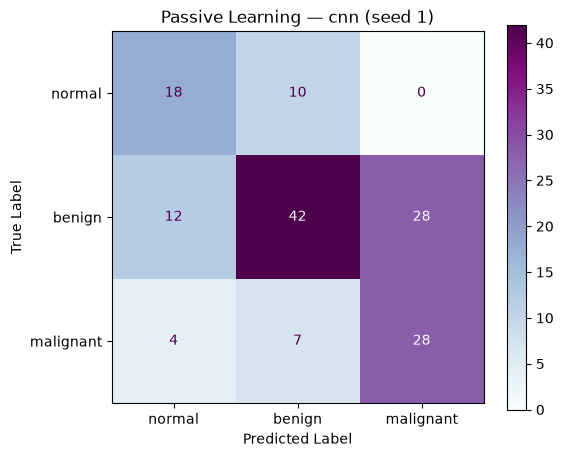

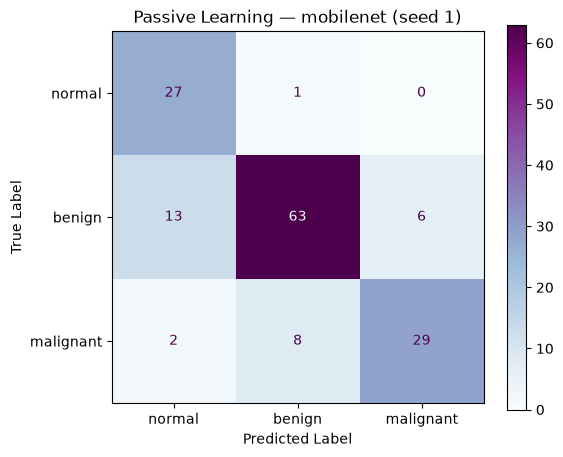

In [7]:
from src.evaluation import plot_confusion_matrix

for name in runs:
    plot_confusion_matrix(y_test, runs[name][0]["y_pred"], title=f"Passive Learning — {name} (seed 1)")

### Exemplos de previsões
Imagens do teste com a classe real e a prevista pela **MobileNetV2** (seed 1): título **verde** quando acerta, **vermelho** quando erra.

1. **Todos os falsos negativos**: os erros mais graves. Vale a pena olhar para eles: são lesões pequenas? com contornos regulares, que parecem benignas? imagens com pouco contraste ou anotações do ecógrafo? (Duas imagens iguais são cópias da mesma ecografia, que ficam sempre no mesmo conjunto.)
2. **Outros erros**: imagens normais ou benignas classificadas com a classe errada (incluindo falsos positivos).
3. **Acertos**: alguns exemplos de cada classe, ao acaso, para comparar.

Estas imagens mostram *o que* o modelo errou, mas não *porquê*. Para isso serve o Grad-CAM (notebook 03), que mostra em que zona da imagem o modelo se baseou.

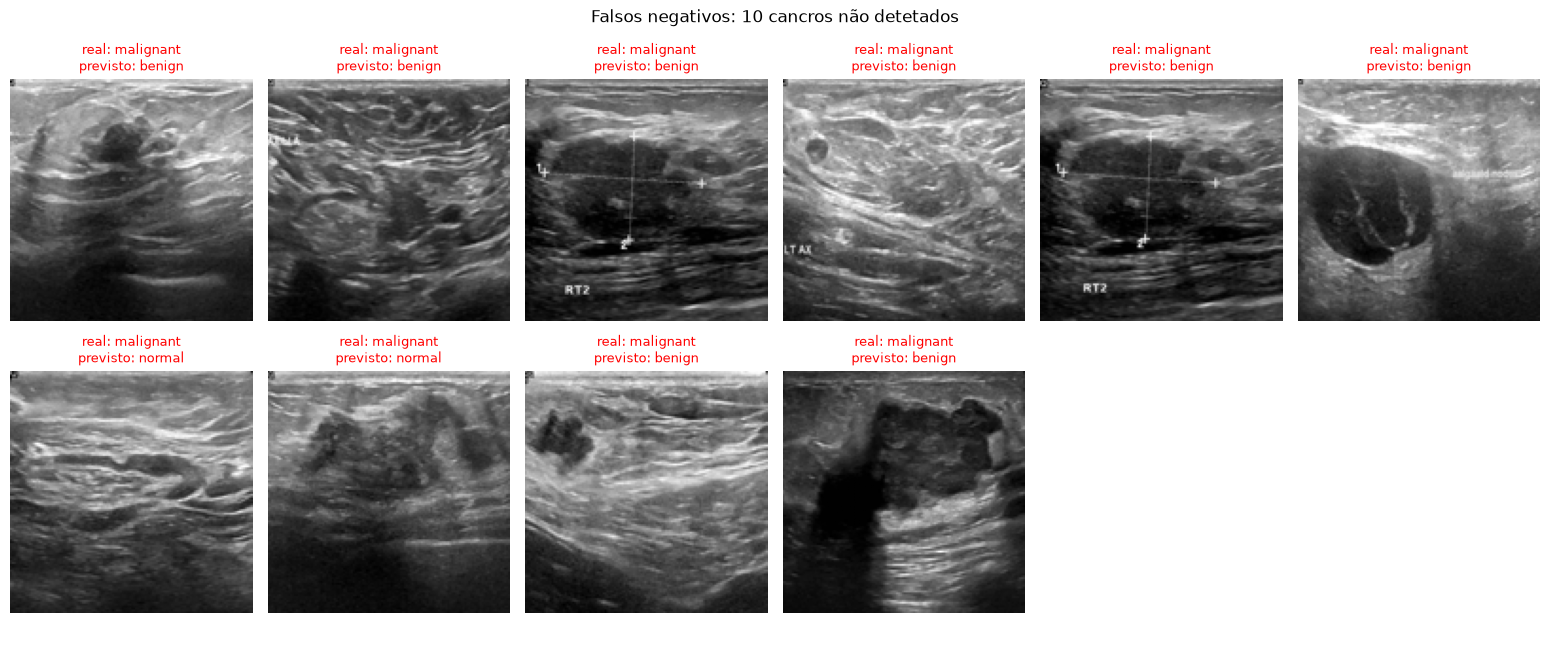

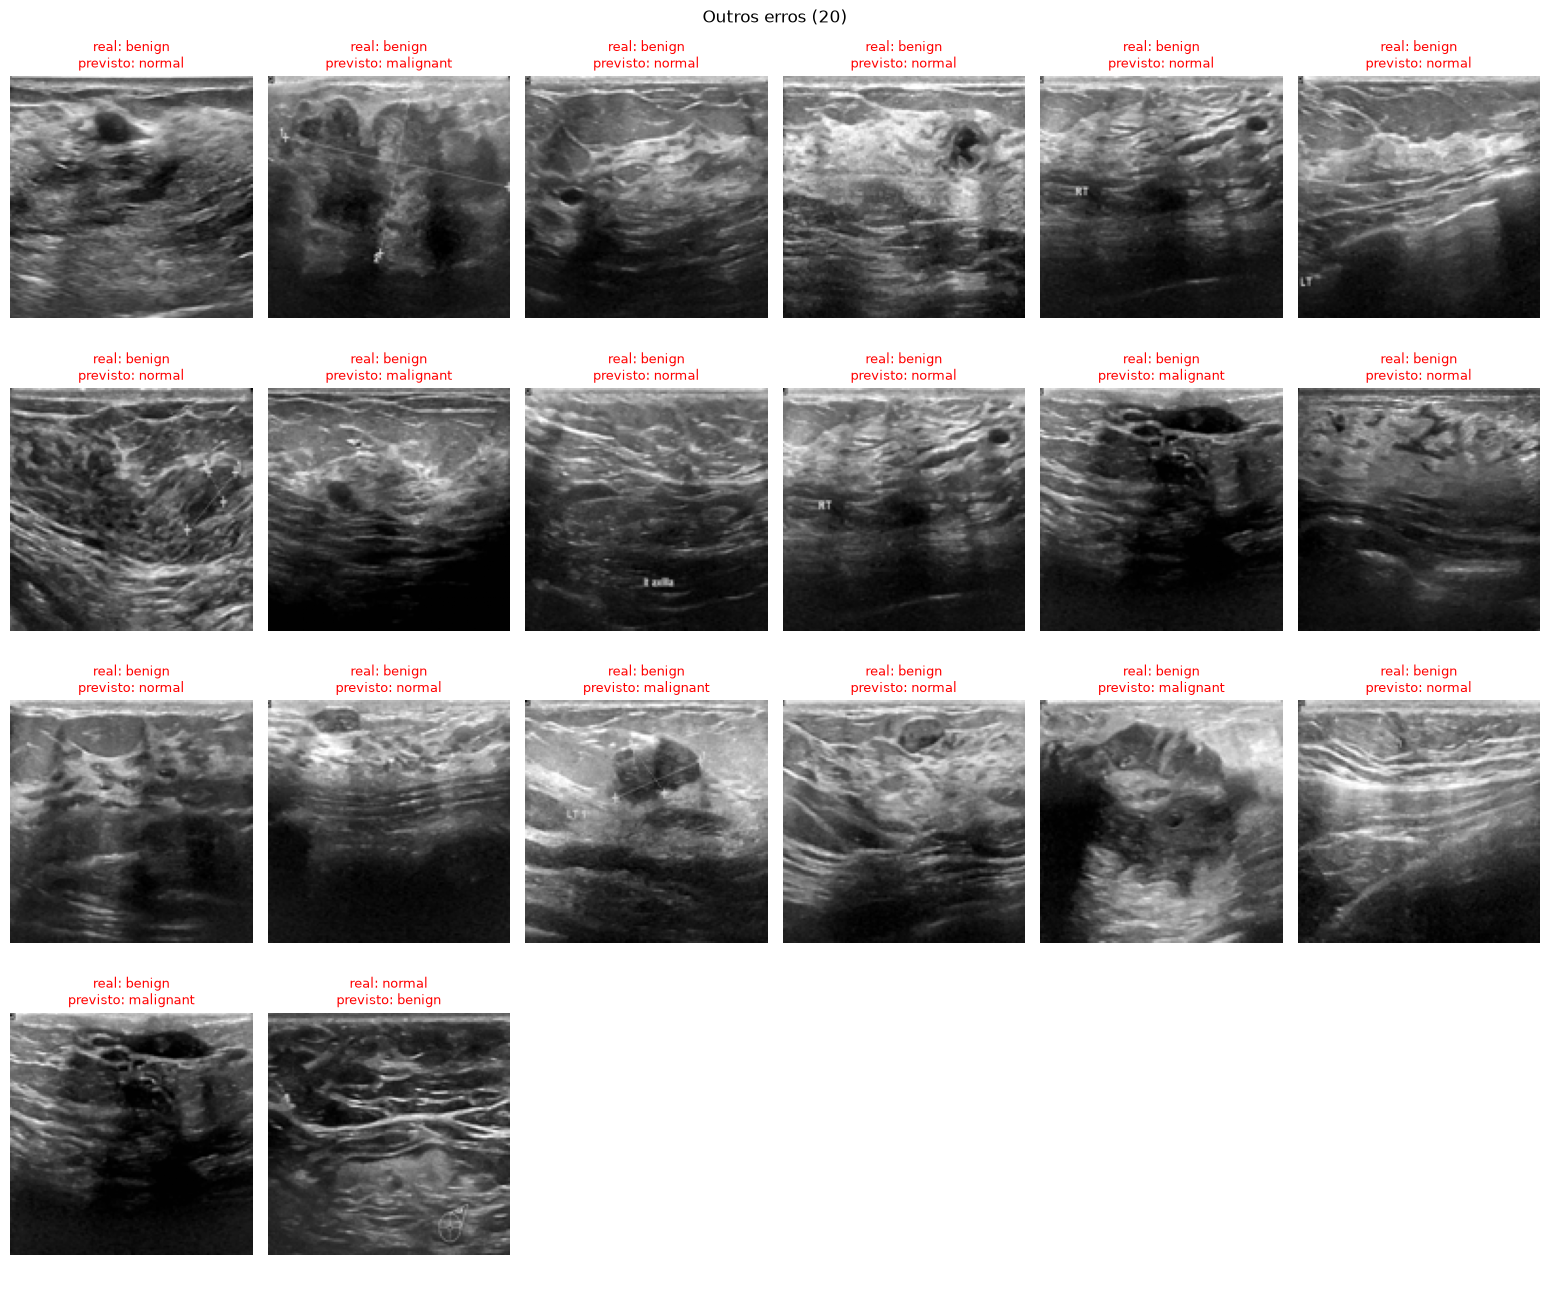

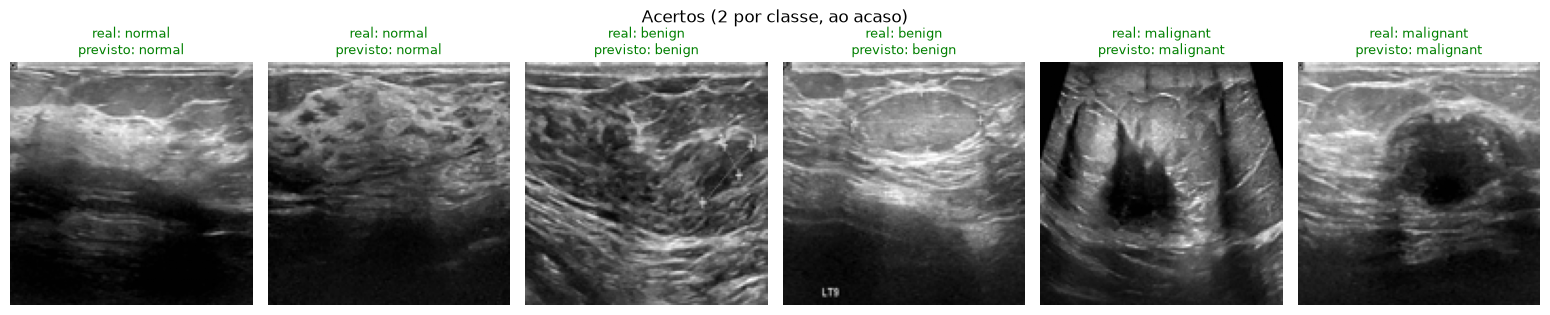

In [8]:
from src.evaluation import MALIGNANT, plot_predictions

y_pred = np.array(runs["mobilenet"][0]["y_pred"])
false_negatives = np.where((y_test == MALIGNANT) & (y_pred != MALIGNANT))[0]
other_errors = np.where((y_test != MALIGNANT) & (y_pred != y_test))[0]
rng = np.random.default_rng(0)
correct = np.concatenate([rng.choice(np.where((y_test == c) & (y_pred == c))[0], 2, replace=False)
                          for c in range(len(CLASSES))])

plot_predictions(x_test, y_test, y_pred, false_negatives, f"Falsos negativos: {len(false_negatives)} cancros não detetados")
plot_predictions(x_test, y_test, y_pred, other_errors, f"Outros erros ({len(other_errors)})")
plot_predictions(x_test, y_test, y_pred, correct, "Acertos (2 por classe, ao acaso)")

## 6. Conclusões

**Resultados no teste (média ± desvio padrão de 5 seeds; 149 imagens, 39 malignas):**

| Modelo | Accuracy | Recall maligno | Falsos negativos |
|---|---|---|---|
| CNN (lr 0.001 + early stopping) | 0.609 ± 0.060 | 0.718 ± 0.093 | 11.0 ± 3.6 |
| **MobileNetV2 + fine-tuning** | **0.804 ± 0.022** | 0.697 ± 0.050 | 11.8 ± 1.9 |

1. **A CNN treinada de raiz é fraca e instável:** conforme a seed, a accuracy vai de 0.55 a 0.71. O recall de maligno é parecido com o da MobileNetV2, mas à custa de classificar muitas imagens benignas e normais como malignas.
2. **O transfer learning é a maior melhoria:** a MobileNetV2 chega a 0.80 de accuracy (contra 0.61) e varia menos entre seeds.
3. **As ecografias repetidas inflacionavam os resultados.** Com a divisão antiga, em que cópias da mesma ecografia podiam ficar no treino e no teste, a MobileNetV2 tinha 0.84 de accuracy e 0.80 de recall de maligno. Com a divisão por grupos, desce para 0.80 e 0.70. Estes números são mais baixos, mas são os honestos.
4. **Os falsos negativos continuam a ser o problema:** o melhor modelo falha, em média, 12 dos 39 cancros do teste (entre 10 e 15, conforme a seed). Alguns dos cancros falhados têm lesões de contornos regulares, que parecem benignas. O modelo não chega para decidir sozinho: o humano tem de continuar no ciclo.
5. **Ambos os modelos fazem overfitting:** a accuracy de treino chega a ~96–100% e a de validação fica em ~72–86%. O early stopping guarda a melhor época, mas o modelo decora parte do treino.
6. **O treino é reprodutível:** a mesma seed dá sempre o mesmo modelo (`setup_gpu`). Sem isso, o recall de maligno da MobileNetV2 com a seed 1 chegou a passar de 0.74 para 0.64 só por voltar a correr.